![Banner](../images/02_kriging.png)

# Kriging



Kriging predicts a value at a place you did not sample, using the places you did. Soil metals, rainfall, ore grade, elevation: any quantity that is more alike at short distances than at long ones. The predictor is a weighted average of the measurements. The weights are the ones that make the average **unbiased** and give it the **smallest error variance** the variogram allows. The same solution returns that error variance, so every prediction comes with a map of how far it can be trusted.

This notebook is the map for classic kriging in GeoLattice. It states the shared estimator, shows where simple, ordinary, universal, and cokriging part company, and runs simple and ordinary kriging through `geolattice.geostatistics` on a six-point example. Five notebooks follow. Four apply the same classes to the Jura cadmium survey, with a held-out test set, model selection, and probability maps. The fifth repeats all four estimators on Great Plains soil organic carbon and compares the core solver with JAX.

 Six notebooks take the kriging weights from a six-point example to a soil map.

- **Kriging.** This notebook. The shared linear system, and simple and ordinary kriging on six points with a known spherical variogram.
- **Simple Kriging.** Jura cadmium, with the mean treated as known. A train and test split, model choice, exceedance probabilities, and a CPU and GPU timing check.
- **Ordinary Kriging.** The same Jura workflow with an unknown constant mean.
- **Universal Kriging.** The mean is a polynomial of the coordinates. Degree choice, a residual variogram, and the trend surface beside the kriging surface.
- **Cokriging.** Cadmium with zinc and nickel. Full and colocated cokriging, and a design in which cadmium is the sparse variable.
- **Simple, ordinary, universal, and cokriging on Great Plains SOC.** Simple, ordinary, universal, and cokriging of soil organic carbon at 5,000 samples, and a core versus JAX timing comparison. Cokriging uses NDVI.

Library: `geolattice.geostatistics`



## Table of Contents

- [What this chapter covers](#what-this-chapter-covers)
1. [Notebooks in this chapter](#1-notebooks-in-this-chapter)
2. [What kriging is](#2-what-kriging-is)
3. [How kriging works](#how-kriging-works)
    - 3.1 [From the variogram to the covariance](#from-the-variogram-to-the-covariance)
    - 3.2 [One linear system](#one-linear-system)
    - 3.3 [What the matrix does to the weights](#what-the-matrix-does-to-the-weights)
    - 3.4 [Kriging variance](#kriging-variance)
4. [The four classic estimators](#the-four-classic-estimators)
5. [Kriging in GeoLattice](#kriging-in-geolattice)
6. [Python setup](#python-setup)
7. [A six-point kriging system](#a-six-point-kriging-system)
8. [Where the next notebooks go](#where-the-next-notebooks-go)
9. [Resources](#resources)
    - 9.1 [Textbooks](#textbooks)
    - 9.2 [Papers and origins](#papers-and-origins)
    - 9.3 [In this library](#in-this-library)



## Overview


Write the quantity of interest as a random field $Z(\mathbf{x})$. At sampled locations $\mathbf{x}_1,\ldots,\mathbf{x}_n$ you observe $Z(\mathbf{x}_i)$. At an unsampled location $\mathbf{x}_0$ every linear kriging predictor has the form

$$
\hat Z(\mathbf{x}_0) = m(\mathbf{x}_0) + \sum_{i=1}^{n} \lambda_i \bigl(Z(\mathbf{x}_i) - m(\mathbf{x}_i)\bigr),
$$

where $m(\mathbf{x})$ is the mean you are willing to assume. Simple kriging plugs in a known constant. Ordinary kriging forces the weights to sum to 1 so an unknown constant cancels. Universal kriging does the same for every coefficient of a polynomial. Cokriging adds a second sum, over a correlated variable.

Two properties define the weights:

1. **Unbiasedness.** $\mathbb{E}[\hat Z(\mathbf{x}_0) - Z(\mathbf{x}_0)] = 0$ under the mean model.
2. **Minimum variance.** Among linear unbiased predictors, $\mathrm{Var}(\hat Z(\mathbf{x}_0) - Z(\mathbf{x}_0))$ is as small as the covariance model allows.

That pair is why the literature calls kriging the best linear unbiased predictor (BLUP). Inverse-distance weighting also averages neighbours. It chooses weights from distance alone, so two samples sitting on top of each other are both counted, and it has no error variance to report. Kriging uses the variogram for both jobs: closer, less redundant samples get more weight, and the minimized variance is the kriging variance.

The working hypothesis is Tobler's: near things are more alike than distant things. The variogram measures how fast that alikeness fades.


---

## How kriging works

### From the variogram to the covariance

The experimental semivariogram averages half the squared difference of pairs separated by lag $h$:

$$
\hat\gamma(h) = \frac{1}{2N(h)}\sum_{(i,j)}\bigl(Z(\mathbf{x}_i)-Z(\mathbf{x}_j)\bigr)^2.
$$

Kriging does not interpolate those points. It evaluates a fitted, authorized model (spherical, exponential, Gaussian, Matérn, stable, or cubic). Under second-order stationarity the covariance and the variogram are the same information:

$$
C(h) = C(0) - \gamma(h), \qquad C(0) = c_0 + c,
$$

with $c_0$ the nugget and $c$ the partial sill. GeoLattice builds the kriging matrix from $C(h)$ and restores $C(0)$ on the diagonal, so the nugget stays in the variance of each sample. Ordinary kriging can also be written with $-\gamma(h)$ and needs only intrinsic stationarity (the variance of increments). The covariance form below is the one `geolattice.geostatistics` solves.

Three numbers on the fitted curve control the weights:

| Parameter | Role in the predictor |
|---|---|
| **Nugget** $c_0$ | Variance at a sample that is not shared with its neighbours (measurement error, or variation finer than the sampling) |
| **Partial sill** $c$ | Spatially structured variance. $C(0) = c_0 + c$ |
| **Range** $a$ | Distance at which $C(h)$ has effectively died. Past the range, a sample does not inform $\mathbf{x}_0$ |

### One linear system

Collect the covariances among the samples in $\mathbf{C}$ and the covariances between the samples and the target in $\mathbf{c}_0$. The weights solve

$$
\begin{bmatrix}
\mathbf{C} & \mathbf{F} \\
\mathbf{F}^\top & \mathbf{0}
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda} \\
\boldsymbol{\mu}
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\
\mathbf{f}_0
\end{bmatrix}.
$$

$\mathbf{F}$ holds the basis functions of the mean at the samples, $\mathbf{f}_0$ holds them at $\mathbf{x}_0$, and $\boldsymbol{\mu}$ holds the Lagrange multipliers that enforce unbiasedness. Then

$$
\hat Z(\mathbf{x}_0) = \boldsymbol{\lambda}^\top \mathbf{z}
$$

for ordinary and universal kriging (the constraints already removed the unknown mean). Simple kriging has no constraint block: $\mathbf{C}\boldsymbol{\lambda} = \mathbf{c}_0$, and the known mean is added back,

$$
\hat Z_{\mathrm{SK}}(\mathbf{x}_0) = m + \boldsymbol{\lambda}^\top (\mathbf{z} - m\mathbf{1}).
$$

The left-hand matrix depends only on the samples. The right-hand side is rebuilt at every target, which is why a fitted model predicts a whole grid with one factorization.

### What the matrix does to the weights

- **Distance.** A sample with a large $C(\mathbf{x}_i-\mathbf{x}_0)$, close, inside the range, pulls a larger weight.
- **Declustering.** Two samples that are close to each other have a large $C(\mathbf{x}_i-\mathbf{x}_j)$. The matrix treats them as nearly the same piece of information and splits the weight, rather than adding both.
- **Screening.** A sample hidden behind a closer one can receive a small **negative** weight. The negative weight stops the cluster from being counted twice. It is a correct solution of the system, and the prediction can then fall slightly outside the range of the neighbouring values.

### Kriging variance

The minimized error variance at $\mathbf{x}_0$ is

$$
\sigma^2(\mathbf{x}_0) = C(0) - \boldsymbol{\lambda}^\top \mathbf{c}_0 - \boldsymbol{\mu}^\top \mathbf{f}_0.
$$

Simple kriging drops the $\boldsymbol{\mu}$ term. `predict(..., return_variance=True)` returns the **standard error** $\sigma(\mathbf{x}_0) = \sqrt{\sigma^2(\mathbf{x}_0)}$, in the units of $Z$.

Read that map as a map of constraint, not as a map of $Z$. It is small beside a sample (down to the nugget, for a continuous model) and it grows toward $C(0)$ in empty parts of the domain, beyond the range. A large nugget keeps $\sigma$ large everywhere, because even a sample does not determine the value at its own location.

If the prediction error is treated as Gaussian,

$$
P\bigl(Z(\mathbf{x}_0) > z_c\bigr) = 1 - \Phi\!\left(\frac{z_c - \hat Z(\mathbf{x}_0)}{\sigma(\mathbf{x}_0)}\right).
$$

The method notebooks map that probability for cadmium cutoffs and score it with the Brier score. Cadmium is right-skewed, so the Gaussian probability is an approximation. Indicator kriging, later in the geostatistics series, estimates the same probability without that assumption.


---

## The four classic estimators

The four notebooks differ by the contents of $\mathbf{F}$ and by whether a second variable is in $\mathbf{z}$.

| | Simple | Ordinary | Universal | Ordinary cokriging |
|---|---|---|---|---|
| Mean | Known constant $m$ | Unknown constant | Unknown polynomial $m(x, y)$ | Unknown constant for each variable |
| Data in the sum | $Z$ | $Z$ | $Z$ | $Z$ and one or more secondaries |
| Constraint | none | $\sum \lambda_i = 1$ | $\mathbf{F}^\top\boldsymbol{\lambda} = \mathbf{f}_0$ | $\sum \lambda_Z = 1$ and $\sum \lambda_{\text{secondary}} = 0$ |
| Variogram | of $Z$ | of $Z$ | of the **residuals** of $Z$ | auto-variograms and a cross-variogram (an LMC) |
| System size | $n$ | $n+1$ | $n+p$ | $n_Z + n_{\text{secondary}} + 2$ |
| Typical use | A stationary field whose global mean is trusted | The default environmental map | A clear spatial trend (a slope, a bowl) | The target is sparse and a correlated variable is denser |

A few consequences follow directly from the constraints.

**Simple kriging spends no degree of freedom on the mean**, so its variance is smaller than ordinary kriging when $m$ is right. A wrong $m$ makes simple kriging biased: far from every sample, $\hat Z$ falls back to that $m$.

**Ordinary kriging is unbiased without knowing $m$.** If the true mean is the constant $m$, then $\mathbb{E}[\sum \lambda_i Z(\mathbf{x}_i)] = m\sum\lambda_i = m$. The price is the extra $-\mu$ in the variance. Degree 0 of universal kriging is ordinary kriging.

**Universal kriging** writes $Z(\mathbf{x}) = m(\mathbf{x}) + R(\mathbf{x})$ with $m$ a polynomial and $R$ a zero-mean residual. In two dimensions a linear drift has three coefficients ($1$, $x$, $y$) and a quadratic drift has six. The weights reproduce each basis function at $\mathbf{x}_0$, so the predictor is unbiased for every coefficient even though the coefficients themselves are unknown. The variogram passed to the solver is the variogram of $R$, estimated in practice from the residuals of a first ordinary-least-squares trend. The universal-kriging notebook compares polynomial degrees before that fit.

**Cokriging** predicts the primary from its own samples and from secondary samples:

$$
\hat Z_1(\mathbf{x}_0) = \sum_{i=1}^{n_1}\lambda_{1i} Z_1(\mathbf{x}_{1i}) + \sum_{j=1}^{n_2}\lambda_{2j} Z_2(\mathbf{x}_{2j}).
$$

Secondary weights sum to **zero**, so zinc can sharpen the cadmium map through its spatial contrast and cannot shift the cadmium mean. The cross-covariance has to be a valid partner of the two auto-covariances. GeoLattice enforces that with a linear model of coregionalization (LMC): every auto- and cross-variogram shares the same basic structures, and the nugget and sill matrices are positive semi-definite. When every variable is measured at the same sites (isotopic sampling), full cokriging is often close to ordinary kriging of the primary alone. The gain appears when the secondary is denser, or known on the whole grid. The cokriging notebook compares full cokriging, colocated cokriging, and ordinary kriging on both designs.


---

## Kriging in GeoLattice

The classes live in `geolattice.geostatistics`. Each one takes a **fitted** variogram, stores the samples in `fit`, and solves the system in `predict`.

| Class | Constructor | Mean model |
|---|---|---|
| `Variogram` | `Variogram(coords, values, model=..., n_lags=..., use_gpu=...)` then `.fit()` | n/a |
| `SimpleKriging` | `SimpleKriging(variogram, mean=None, use_gpu=...)` | `mean`, or the sample mean if `mean` is omitted |
| `OrdinaryKriging` | `OrdinaryKriging(variogram, use_gpu=...)` | unknown constant |
| `UniversalKriging` | `UniversalKriging(variogram, degree=1, use_gpu=...)` | polynomial of `degree`; pass a **residual** variogram |
| `Cokriging` | `Cokriging(primary_var, secondary_var, cross_var, use_gpu=...)` | ordinary cokriging, one secondary |
| `CrossVariogram`, `fit_lmc` | build the cross-structure the cokriging matrix needs | n/a |
| `MultivariateCokriging`, `ColocatedCokriging` | several secondaries; full or Markov (MM1) colocated | used in the cokriging notebook |

The call pattern is the same for the univariate estimators:

```python
vg = Variogram(coords, values, model="spherical", n_lags=15, use_gpu=False).fit()
ok = OrdinaryKriging(vg, use_gpu=False).fit(coords, values)
z_hat, se = ok.predict(grid, return_variance=True)
```

`coords` and `grid` are arrays of shape `(n, 2)`. `z_hat` is the prediction. `se` is the kriging **standard error**.

`use_gpu` is `'auto'` (the default), `True`, or `False`. `'auto'` runs the covariance build and the solve on the GPU when CuPy can execute a kernel, and stays on CPU otherwise. This introduction passes `use_gpu=False` so the arithmetic is the same on a laptop and on a CUDA machine. The method notebooks time both backends.

`OrdinaryKriging.predict(..., block_size=...)` approximates block kriging by averaging point predictions inside a square. Point support is the right object for a concentration at a sample location; block support is the right object for a mean over a panel. The method notebooks stay on point support.

Two practical rules, applied in every later notebook:

- Fit the variogram on the **training** samples only. A variogram that has seen the test set makes the validation optimistic.
- For simple kriging, take $m$ from the training sample as well. For universal kriging, fit the residual variogram on the training residuals.


---

## Python setup


**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore", category=UserWarning)

import geolattice.geostatistics as gstat
from geolattice.geostatistics import Variogram, SimpleKriging, OrdinaryKriging

USE_GPU = False  # identical arithmetic on CPU and GPU machines; method notebooks time both

print(f"geolattice.geostatistics : {gstat.__version__}")


geolattice.geostatistics : 0.3.49


---

## A six-point kriging system

Six measurements and one target are enough to see the weights. The variogram is a spherical model with nugget $0.02$, partial sill $0.60$, and range $1.4$ (set with `set_params`, so the curve is known exactly). Points P1 and P2 sit close together. P2 is between P1 and the target, so P1 is a candidate for screening.

The covariance helper below is the same transform GeoLattice uses: $C(h) = C(0) - \gamma(h)$, with $C(0)$ written back onto zero distance.


In [2]:
samples = pd.DataFrame({
    "point": ["P1", "P2", "P3", "P4", "P5", "P6"],
    "x": [0.00, 0.15, 1.20, 0.10, 1.00, 0.55],
    "y": [0.00, 0.05, 0.10, 1.10, 1.00, 0.85],
    "z": [2.2, 2.0, 0.7, 1.5, 0.4, 1.1],
})
coords6 = samples[["x", "y"]].to_numpy()
z6 = samples["z"].to_numpy()
target = np.array([[0.65, 0.35]])

vg6 = Variogram(coords6, z6, model="spherical", n_lags=4, use_gpu=False)
vg6.set_params(nugget=0.02, sill=0.60, range_=1.4)

def covariance(variogram, dist):
    """C(h) = C(0) - gamma(h), with C(0) restored at h = 0."""
    c0 = float(variogram.fitted_params[0] + variogram.fitted_params[1])
    cov = c0 - np.asarray(variogram(dist), dtype=float)
    cov = np.array(cov, dtype=float, copy=True)
    cov[np.asarray(dist) == 0.0] = c0
    return cov, c0

dist_samples = cdist(coords6, coords6)
dist_target = cdist(target, coords6)[0]
C, C0 = covariance(vg6, dist_samples)
c0, _ = covariance(vg6, dist_target)

mean6 = float(z6.mean())
lam_sk = np.linalg.solve(C, c0)
z_sk = mean6 + lam_sk @ (z6 - mean6)
se_sk = np.sqrt(C0 - lam_sk @ c0)

n = len(z6)
K = np.block([
    [C, np.ones((n, 1))],
    [np.ones((1, n)), np.zeros((1, 1))],
])
sol = np.linalg.solve(K, np.r_[c0, 1.0])
lam_ok, mu_ok = sol[:-1], sol[-1]
z_ok = lam_ok @ z6
se_ok = np.sqrt(max(C0 - lam_ok @ c0 - mu_ok, 0.0))

sk6 = SimpleKriging(vg6, mean=mean6, use_gpu=USE_GPU).fit(coords6, z6)
ok6 = OrdinaryKriging(vg6, use_gpu=USE_GPU).fit(coords6, z6)
api_sk, api_sk_se = sk6.predict(target, return_variance=True)
api_ok, api_ok_se = ok6.predict(target, return_variance=True)

weights = samples.copy()
weights["distance"] = dist_target
weights["SK weight"] = lam_sk
weights["OK weight"] = lam_ok
weights = weights.round({"distance": 3, "SK weight": 3, "OK weight": 3, "z": 2})
print(weights.to_string(index=False))
print()
print(f"SK weights sum to {lam_sk.sum():.3f}    prediction {z_sk:.3f}    SE {se_sk:.3f}")
print(f"OK weights sum to {lam_ok.sum():.3f}    prediction {z_ok:.3f}    SE {se_ok:.3f}    mu {mu_ok:.4f}")
print(f"SimpleKriging.predict   {api_sk[0]:.3f}  SE {api_sk_se[0]:.3f}")
print(f"OrdinaryKriging.predict {api_ok[0]:.3f}  SE {api_ok_se[0]:.3f}")


point    x    y   z  distance  SK weight  OK weight
   P1 0.00 0.00 2.2     0.738     -0.064     -0.057
   P2 0.15 0.05 2.0     0.583      0.366      0.369
   P3 1.20 0.10 0.7     0.604      0.303      0.311
   P4 0.10 1.10 1.5     0.930     -0.063     -0.055
   P5 1.00 1.00 0.4     0.738      0.045      0.052
   P6 0.55 0.85 1.1     0.510      0.381      0.381

SK weights sum to 0.968    prediction 1.188    SE 0.598
OK weights sum to 1.000    prediction 1.186    SE 0.599    mu -0.0059
SimpleKriging.predict   1.188  SE 0.598
OrdinaryKriging.predict 1.186  SE 0.599


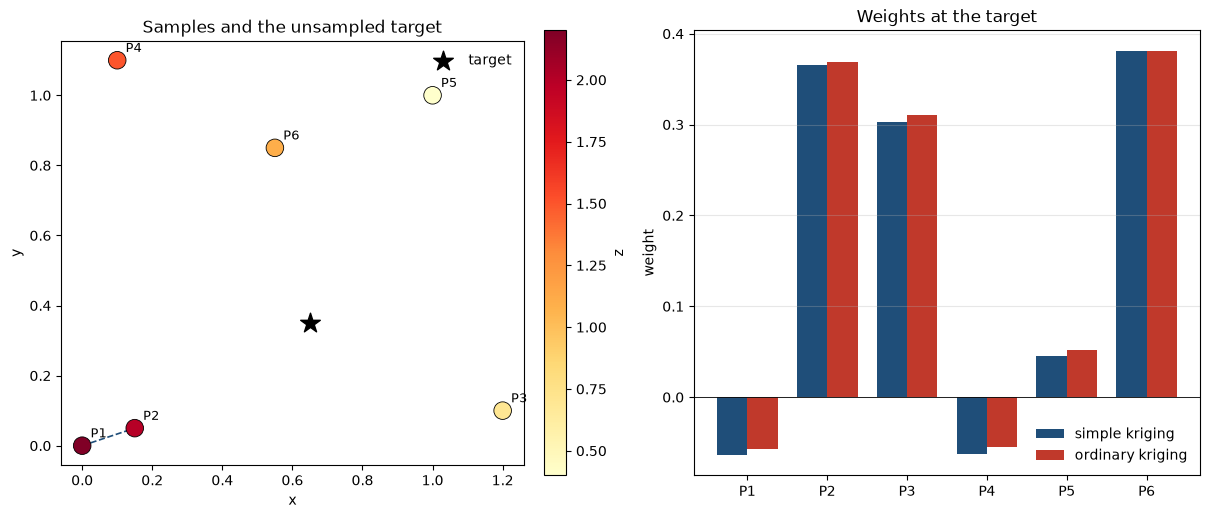

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.2))

ax = axes[0]
sc = ax.scatter(samples["x"], samples["y"], c=samples["z"], cmap="YlOrRd",
                s=160, edgecolors="k", linewidths=0.6, zorder=3)
for _, row in samples.iterrows():
    ax.annotate(row["point"], (row["x"], row["y"]),
                textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.scatter(target[0, 0], target[0, 1], marker="*", s=220, c="k", zorder=4, label="target")
ax.plot([0.00, 0.15], [0.00, 0.05], color="#1f4e79", lw=1.2, ls="--", zorder=2)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Samples and the unsampled target")
ax.legend(frameon=False, loc="upper right")
plt.colorbar(sc, ax=ax, label="z", fraction=0.046, pad=0.04)

ax = axes[1]
x = np.arange(len(samples))
width = 0.38
ax.bar(x - width / 2, lam_sk, width, color="#1f4e79", label="simple kriging")
ax.bar(x + width / 2, lam_ok, width, color="#c0392b", label="ordinary kriging")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(x, samples["point"])
ax.set_ylabel("weight")
ax.set_title("Weights at the target")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


P2, P3, and P6 carry almost all of the weight. They are the three samples nearest the target and still inside the range. P1 sits beside P2 and a little farther from the target, so the system gives P1 a small negative weight and gives P2 the cluster's share. P4 is the farthest sample and is slightly negative as well. Simple-kriging weights sum to less than 1; the shortfall is the pull back toward the known mean. Ordinary-kriging weights sum to 1, and the standard error is a little larger, which is the cost of that extra constraint. Both predictions match `SimpleKriging.predict` and `OrdinaryKriging.predict`.


---

## Where the next notebooks go

The calls above are the whole univariate API: fit a variogram, construct the estimator, `fit` the samples, `predict` a grid. What they leave out is the evidence that the map is any good.

| Next notebook | What it adds to the call you just ran |
|---|---|
| [Simple kriging](05_02_01_simple_kriging.ipynb) | Train / test split by land use, AIC model choice, test RMSE and standardized residuals, exceedance probabilities, CPU vs GPU |
| [Ordinary kriging](05_02_02_ordinary_kriging.ipynb) | The same workflow with an unknown mean, which is the usual default for a soil map |
| [Universal kriging](05_02_03_universal_kriging.ipynb) | Choosing the polynomial degree, fitting the residual variogram, and reading the trend surface beside the kriging surface |
| [Cokriging](05_02_04_cokriging.ipynb) | The LMC in detail, full vs colocated cokriging, and a heterotopic design in which cadmium is the sparse variable |

Open simple kriging first if the mean model is the part you want to see tested. Open cokriging first if the question is already a second variable.


---

## Resources

### Textbooks

| Reference | What to read it for |
|---|---|
| Isaaks, E.H. & Srivastava, R.M. (1989). *An Introduction to Applied Geostatistics*. Oxford. | The weight equations, with numbers small enough to check by hand |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford. | The Jura metals, and SK vs OK vs cokriging on that survey |
| Webster, R. & Oliver, M.A. (2007). *Geostatistics for Environmental Scientists* (2nd ed.). Wiley. | Environmental sampling, the nugget, and how to read a kriging variance |
| Chilès, J.-P. & Delfiner, P. (2012). *Geostatistics: Modeling Spatial Uncertainty* (2nd ed.). Wiley. | The BLUP derivation and the universal-kriging system |
| Wackernagel, H. (2003). *Multivariate Geostatistics* (3rd ed.). Springer. | The linear model of coregionalization |

### Papers and origins

| Reference | Contribution |
|---|---|
| Krige, D.G. (1951). A statistical approach to some mine valuation and allied problems on the Witwatersrand. MSc thesis, University of the Witwatersrand. | The mining problem the estimator is named for |
| Matheron, G. (1963). Principles of geostatistics. *Economic Geology* 58, 1246-1266. | The random-field statement of simple and ordinary kriging |
| Journel, A.G. & Huijbregts, C.J. (1978). *Mining Geostatistics*. Academic Press. | Screening, negative weights, and the practice of the linear system |

### In this library

| Object | Role |
|---|---|
| `geolattice.geostatistics.Variogram` | Experimental variogram and an authorized fit |
| `SimpleKriging`, `OrdinaryKriging`, `UniversalKriging` | The three univariate systems |
| `fit_lmc`, `Cokriging`, `MultivariateCokriging`, `ColocatedCokriging` | Cross-variograms and cokriging |
| `predict(..., return_variance=True)` | Prediction and kriging standard error |
